# Session 26 Solutions: Describing Data with Statistics

Data Science with Python, Level 2, Stage 4: Statistics

Try each exercise yourself before reading its solution. There is usually more than one correct answer; compare your approach with this one.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
DATA_URL = "https://raw.githubusercontent.com/mohammadyahoo/ds-python-course/main/data/"
exams = pd.read_csv(DATA_URL + "exam_scores.csv")

## In-Class Exercises

### In-Class Exercise 1: Describe Physics

In [2]:
p = exams["physics"]
q1, q3 = p.quantile([0.25, 0.75])
print(round(p.mean(), 1), p.median(), round(p.std(), 1), q3 - q1)
print("Skew:", round(p.skew(), 2))

51.7 51.0 11.4 15.0
Skew: -0.03


### In-Class Exercise 2: Check the Rule

In [3]:
e = exams["english"]
for k in [1, 2, 3]:
    print(k, round(e.between(e.mean() - k * e.std(), e.mean() + k * e.std()).mean(), 3))

1 0.678
2 0.948
3 1.0


### In-Class Exercise 3: Top Ten Percent

In [4]:
cut = exams["math"].quantile(0.9)
print(cut, (exams["math"] >= cut).sum())

75.0 51


### In-Class Exercise 4: Best Relative Result

In [5]:
cols = ["math", "physics", "english"]
z = (exams[cols] - exams[cols].mean()) / exams[cols].std()
print(z.idxmax(axis=1).value_counts())

english    199
physics    157
math       144
Name: count, dtype: int64


## Part A: Basic

### Exercise 1: Summary Table

In [6]:
cols = ["math", "physics", "english"]
exams[cols].agg(["mean", "median", "std", "min", "max"]).T.round(1)

,mean,median,std,min,max
math,56.7,57.0,13.3,11.0,95.0
physics,51.7,51.0,11.4,15.0,87.0
english,67.3,67.0,7.6,47.0,90.0


### Exercise 2: Sleep Hours

7.08 1.08 0.156


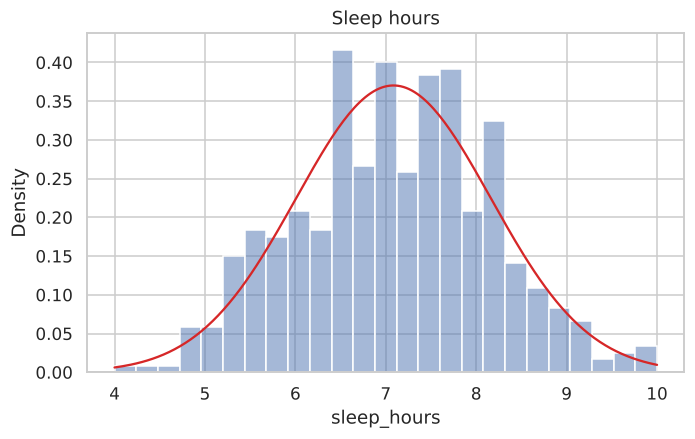

In [7]:
s = exams["sleep_hours"]
print(round(s.mean(), 2), round(s.std(), 2), round((s < 6).mean(), 3))
x = np.linspace(s.min(), s.max(), 200)
sns.histplot(s, bins=25, stat="density", alpha=0.5)
plt.plot(x, stats.norm.pdf(x, s.mean(), s.std()), color="tab:red")
plt.title("Sleep hours")
plt.show()

## Part B: Intermediate

### Exercise 3: Normal Probabilities

In [8]:
mu, sd = exams["math"].mean(), exams["math"].std()
print("Model below 40:", round(stats.norm.cdf(40, mu, sd), 3), "real:", round((exams["math"] < 40).mean(), 3))
print("Model above 80:", round(1 - stats.norm.cdf(80, mu, sd), 3), "real:", round((exams["math"] > 80).mean(), 3))

Model below 40: 0.104 real: 0.096
Model above 80: 0.04 real: 0.038


### Exercise 4: Spread by Class

       mean   std
class            
A      57.6  13.2
B      56.4  12.7
C      57.9  14.3
D      56.1  13.5
E      55.9  12.8


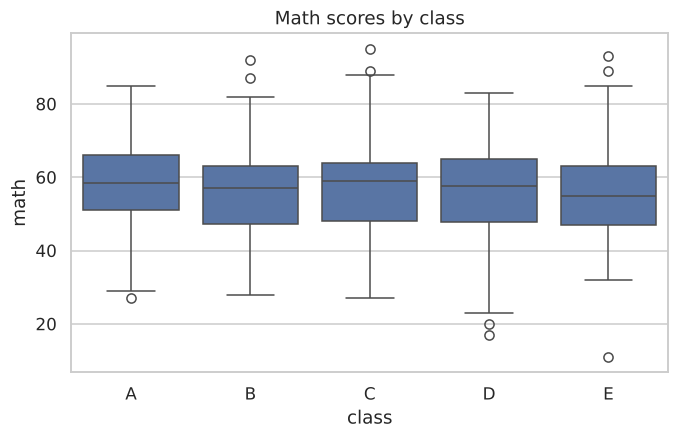

In [9]:
print(exams.groupby("class")["math"].agg(["mean", "std"]).round(1))
sns.boxplot(data=exams, x="class", y="math", order=list("ABCDE"))
plt.title("Math scores by class")
plt.show()

## Part C: Challenge

### Exercise 5: Why n - 1?

Dividing by n is too small on average, because each sample's own mean sits closer to its values than the true mean does. Dividing by n - 1 corrects this.

In [10]:
rng = np.random.default_rng(26)
samples = rng.normal(0, 10, size=(5000, 5))
print("Divide by n:     ", round(samples.var(axis=1, ddof=0).mean(), 1))
print("Divide by n - 1: ", round(samples.var(axis=1, ddof=1).mean(), 1))

Divide by n:      80.1
Divide by n - 1:  100.2


## Part D: Cumulative Project: Exam Scores Study

### Exercise 6: Exam Scores Study: Part 1

In [11]:
num = exams.select_dtypes("number").drop(columns="student_id")
table = pd.DataFrame({"mean": num.mean(), "median": num.median(), "std": num.std(),
                      "IQR": num.quantile(0.75) - num.quantile(0.25)}).round(1)
print(table)
for col in ["math", "physics", "english"]:
    s = exams[col]
    within = [round(s.between(s.mean() - k * s.std(), s.mean() + k * s.std()).mean(), 3) for k in (1, 2, 3)]
    print(col, "skew", round(s.skew(), 2), "within 1, 2, 3 std:", within)
# All three subjects are close to normal: small skew and shares close to 68, 95 and 99.7 percent.
for col in ["math", "physics", "english"]:
    exams[col + "_z"] = (exams[col] - exams[col].mean()) / exams[col].std()
exams["overall_z"] = exams[["math_z", "physics_z", "english_z"]].mean(axis=1)
exams.nlargest(5, "overall_z")[["student_id", "study_hours_week", "sleep_hours", "attendance_pct", "overall_z"]].round(2)

                  mean  median   std   IQR
study_hours_week   6.9     6.0   4.0   5.4
sleep_hours        7.1     7.1   1.1   1.4
attendance_pct    87.7    88.0   7.9  12.0
math              56.7    57.0  13.3  17.0
physics           51.7    51.0  11.4  15.0
english           67.3    67.0   7.6  10.0
math skew -0.03 within 1, 2, 3 std: [np.float64(0.682), np.float64(0.952), np.float64(0.998)]
physics skew -0.03 within 1, 2, 3 std: [np.float64(0.682), np.float64(0.956), np.float64(0.996)]
english skew 0.15 within 1, 2, 3 std: [np.float64(0.678), np.float64(0.948), np.float64(1.0)]


,student_id,study_hours_week,sleep_hours,attendance_pct,overall_z
481,482,22.7,7.1,96,2.53
393,394,18.7,8.4,100,2.45
195,196,22.2,8.7,93,2.27
263,264,19.7,7.5,93,2.15
457,458,9.9,6.0,89,1.64


## Part E: Quiz Answers

| Question | Answer | Explanation |
| --- | --- | --- |
| 1 | B | The median depends only on the middle of the sorted values. |
| 2 | B | The standard deviation measures spread. |
| 3 | C | That is the middle part of the 68-95-99.7 rule. |
| 4 | B | z-scores are measured in standard deviations. |
| 5 | B | Percentiles rank a value within the group. |